# Project 2 · Milestone 2 — Notebook 04: Text Encoder + Diffusion Integration and Training

**Goal:** connect the **text encoder** to the **diffusion model** ourselves and show that the text really controls the image.

What this notebook does:
1. Loads the five parts of Stable Diffusion 1.5 **separately** (tokenizer, CLIP text encoder, U-Net, VAE, scheduler).
2. Traces one prompt through the whole path: **text → tokens → embedding → cross-attention in the U-Net → latent → image**, and saves the shape at every step.
3. Runs **our own denoising loop** (no ready-made pipeline) and checks that it gives the same image as the official pipeline.
4. **Conditioning check:** same seed, different prompts. If the text path works, every image matches its own prompt best.
5. **Training:** a small **BERT → CLIP adapter** (about 17M parameters). It learns to turn BERT embeddings into the 77×768 embeddings the U-Net expects. This gives us real loss curves, training time and GPU memory.
6. Compares images made with **CLIP**, **raw BERT** (no adapter) and **BERT + adapter**.

Everything is saved in `m2_integration/` and zipped at the end.

**Runtime:** Colab, **T4 GPU**, about 15–20 minutes (the first model download takes about 5).

## 1. Install

In [3]:
!pip install -q diffusers transformers accelerate
!pip uninstall -y -q torchao   # Colab's old torchao breaks new diffusers; we don't use it

## 2. Settings
Same models and settings as Milestone 1: Stable Diffusion 1.5, CLIP ViT-L/14, 30 steps, guidance scale 7.5, 512×512.

In [4]:
import os, json, time, math, copy, inspect, textwrap, platform
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

SEED        = 42
SD_MODEL    = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CLIP_SCORER = "openai/clip-vit-large-patch14"     # for scoring only
BERT_MODEL  = "bert-base-uncased"
STEPS, GUIDANCE, SIZE = 30, 7.5, 512
OUT = "m2_integration"
os.makedirs(os.path.join(OUT, "images"), exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype  = torch.float16 if device == "cuda" else torch.float32
torch.manual_seed(SEED); np.random.seed(SEED)
GPU = torch.cuda.get_device_name(0) if device == "cuda" else "none"
print("device:", device, "| GPU:", GPU)
if device == "cpu":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU.")

def peak_gb():
    return round(torch.cuda.max_memory_allocated() / 1e9, 2) if device == "cuda" else 0.0

def sync():
    if device == "cuda": torch.cuda.synchronize()

T_START = time.time()

device: cuda | GPU: Tesla T4


## 3. Load our dataset from Milestone 1
**No upload needed.** This cell uses `flickr30k_subset.zip` if it is in the file panel; if not, it downloads `metadata.csv` (the captions and splits) from our GitHub repo. This notebook only needs the **captions**, not the photos. The **check code** must say *same as Milestone 1*.

In [5]:
import os, json, glob, shutil, zipfile, hashlib, urllib.request
import pandas as pd

REPO_RAW = "https://raw.githubusercontent.com/abdul6253/IE7615-group-02-project2/main"
DATA_DIR = "data/flickr30k_subset"
META     = os.path.join(DATA_DIR, "metadata.csv")
os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(META):
    zips = [z for z in glob.glob("*.zip") + glob.glob("*/*.zip")
            if "flickr30k" in z.lower() and zipfile.is_zipfile(z)]
    if zips:
        shutil.unpack_archive(max(zips, key=os.path.getsize), DATA_DIR)
        print("Unzipped", max(zips, key=os.path.getsize))
    else:
        urllib.request.urlretrieve(f"{REPO_RAW}/{META}", META)
        print("Downloaded metadata.csv from our GitHub repo")

df = pd.read_csv(META)
check = hashlib.md5("|".join(sorted(df["filename"] + ":" + df["split"])).encode()).hexdigest()[:10]
print("pairs:", len(df), df["split"].value_counts().to_dict())
print("check code:", check, "(same as Milestone 1)" if check == "477c680542" else "(DIFFERENT from Milestone 1!)")

# The 15 test prompts from Milestone 1 (same captions, same seeds 42 + id)
M1_RESULTS = "baseline_gallery/results.csv"
if not os.path.exists(M1_RESULTS):
    os.makedirs("baseline_gallery", exist_ok=True)
    urllib.request.urlretrieve(f"{REPO_RAW}/{M1_RESULTS}", M1_RESULTS)
m1 = pd.read_csv(M1_RESULTS)
assert set(m1["caption"]) <= set(df.loc[df["split"] == "test", "caption"]), "M1 prompts must come from the test split"
print("Milestone 1 prompts loaded:", len(m1))

Downloaded metadata.csv from our GitHub repo
pairs: 2000 {'train': 1600, 'val': 200, 'test': 200}
check code: 477c680542 (same as Milestone 1)
Milestone 1 prompts loaded: 15


## 4. Load the five parts of Stable Diffusion separately
Instead of one ready-made pipeline, we load each part on its own so we can connect them by hand:

| Part | Job |
|---|---|
| CLIP tokenizer | text → 77 token ids |
| CLIP text encoder (ViT-L/14) | token ids → **77 × 768** embedding (this is the same text encoder as notebook 02) |
| U-Net | removes noise from the latent; reads the text embedding through **cross-attention** |
| VAE | turns the 4×64×64 latent into a 3×512×512 image |
| Scheduler (PNDM) | decides how much noise to remove at each step |

The key check: the U-Net's `cross_attention_dim` must equal the text encoder's hidden size (768), otherwise the text cannot be plugged in.

In [6]:
from transformers import CLIPTokenizer, CLIPTextModel
from diffusers import UNet2DConditionModel, AutoencoderKL, PNDMScheduler, StableDiffusionPipeline
from diffusers.utils.torch_utils import randn_tensor

t0 = time.time()
tokenizer    = CLIPTokenizer.from_pretrained(SD_MODEL, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(SD_MODEL, subfolder="text_encoder").to(device, dtype).eval()
unet         = UNet2DConditionModel.from_pretrained(SD_MODEL, subfolder="unet").to(device, dtype).eval()
vae          = AutoencoderKL.from_pretrained(SD_MODEL, subfolder="vae").to(device, dtype).eval()
scheduler    = PNDMScheduler.from_pretrained(SD_MODEL, subfolder="scheduler")
for m in (text_encoder, unet, vae):
    m.requires_grad_(False)
LOAD_SECS = round(time.time() - t0, 1)

def n_params(m):
    return round(sum(p.numel() for p in m.parameters()) / 1e6, 1)

parts = pd.DataFrame([
    {"part": "CLIP tokenizer",               "job": "text -> 77 token ids",                         "params_M": 0},
    {"part": "CLIP text encoder (ViT-L/14)", "job": "token ids -> 77 x 768 embedding",              "params_M": n_params(text_encoder)},
    {"part": "U-Net",                        "job": "removes noise; reads text by cross-attention", "params_M": n_params(unet)},
    {"part": "VAE",                          "job": "latent 4x64x64 <-> image 3x512x512",           "params_M": n_params(vae)},
    {"part": "PNDM scheduler",               "job": "noise level at each step",                     "params_M": 0},
])
display(parts)
print("U-Net cross_attention_dim:", unet.config.cross_attention_dim,
      "| text encoder hidden size:", text_encoder.config.hidden_size)
assert unet.config.cross_attention_dim == text_encoder.config.hidden_size, "text embedding size does not fit the U-Net"
print(f"Loaded in {LOAD_SECS}s | GPU memory so far: {peak_gb()} GB")

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  492MB            

... (10 outputs left out)

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

,part,job,params_M
0,CLIP tokenizer,text -> 77 token ids,0.0
1,CLIP text encoder (ViT-L/14),token ids -> 77 x 768 embedding,123.1
2,U-Net,removes noise; reads text by cross-attention,859.5
3,VAE,latent 4x64x64 <-> image 3x512x512,83.7
4,PNDM scheduler,noise level at each step,0.0


U-Net cross_attention_dim: 768 | text encoder hidden size: 768
Loaded in 57.8s | GPU memory so far: 2.16 GB


## 5. Trace one prompt through the whole path
We follow one caption from the test split and record the shape of the data at every stage. This is the "text → embedding → conditioning → image" flow the write-up describes.

In [7]:
TRACE_PROMPT = m1.loc[0, "caption"]          # "A tan dog running through the grass ..."

@torch.no_grad()
def clip_embed(texts):
    ids = tokenizer(texts, padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt").input_ids.to(device)
    return text_encoder(ids)[0]              # last hidden state: (batch, 77, 768)

tok = tokenizer(TRACE_PROMPT, padding="max_length", max_length=77, truncation=True, return_tensors="pt")
n_real = int(tok.attention_mask[0].sum())
cond, uncond = clip_embed([TRACE_PROMPT]), clip_embed([""])
lat = randn_tensor((1, unet.config.in_channels, SIZE // 8, SIZE // 8),
                   generator=torch.Generator(device=device).manual_seed(SEED), device=torch.device(device), dtype=dtype)
with torch.no_grad():
    t_first = scheduler.config.num_train_timesteps - 1
    eps = unet(torch.cat([lat] * 2), t_first, encoder_hidden_states=torch.cat([uncond, cond])).sample

trace = {
    "prompt": TRACE_PROMPT,
    "tokens (real, incl. start/end)": n_real,
    "first tokens": tokenizer.convert_ids_to_tokens(tok.input_ids[0][:n_real].tolist()),
    "token ids": list(tok.input_ids.shape),
    "text embedding (cond)": list(cond.shape),
    "empty-prompt embedding (uncond)": list(uncond.shape),
    "embedding fed to U-Net (uncond + cond, for guidance)": [2] + list(cond.shape[1:]),
    "starting noise latent": list(lat.shape),
    "U-Net noise prediction": list(eps.shape),
    "VAE scale factor": vae.config.scaling_factor,
    "final image": [3, SIZE, SIZE],
    "latent vs image size": f"{lat.numel()} numbers vs {3 * SIZE * SIZE} numbers ({3 * SIZE * SIZE // lat.numel()}x smaller)",
}
for k, v in trace.items():
    print(f"{k:55s} {v}")
with open(os.path.join(OUT, "trace.json"), "w") as f:
    json.dump(trace, f, indent=2)

prompt                                                  A tan dog running through the grass with the background blurry
tokens (real, incl. start/end)                          13
first tokens                                            ['<|startoftext|>', 'a</w>', 'tan</w>', 'dog</w>', 'running</w>', 'through</w>', 'the</w>', 'grass</w>', 'with</w>', 'the</w>', 'background</w>', 'blurry</w>', '<|endoftext|>']
token ids                                               [1, 77]
text embedding (cond)                                   [1, 77, 768]
empty-prompt embedding (uncond)                         [1, 77, 768]
embedding fed to U-Net (uncond + cond, for guidance)    [2, 77, 768]
starting noise latent                                   [1, 4, 64, 64]
U-Net noise prediction                                  [2, 4, 64, 64]
VAE scale factor                                        0.18215
final image                                             [3, 512, 512]
latent vs image size                      

## 6. Our own denoising loop
This is the core of the integration. At every step:
1. the latent is copied twice, one copy for the **empty prompt** and one for **our prompt**;
2. the U-Net predicts the noise in both, reading the text embedding through cross-attention;
3. **classifier-free guidance** mixes them: `noise = uncond + guidance × (cond − uncond)`;
4. the scheduler removes that noise.

At the end the VAE turns the latent into the picture. The function takes **embeddings**, not text, so we can plug in any text encoder (CLIP now, BERT later). With `record=True` it also saves **sampler diagnostics**: the latent's spread, how strong the text signal is (`cond − uncond`), and a preview of the image the model "sees" at that step.

In [8]:
def make_scheduler():
    return PNDMScheduler.from_config(scheduler.config)

@torch.no_grad()
def decode(latents):
    img = vae.decode(latents.to(dtype) / vae.config.scaling_factor).sample
    img = (img / 2 + 0.5).clamp(0, 1)[0].permute(1, 2, 0).float().cpu().numpy()
    return Image.fromarray((img * 255).round().astype("uint8"))

PREVIEW_STEPS = [1, 5, 10, 15, 20, 25]   # plus the last step

@torch.no_grad()
def generate(cond, uncond, seed, steps=STEPS, guidance=GUIDANCE, record=False):
    sched = make_scheduler()
    g = torch.Generator(device=device).manual_seed(seed)
    latents = randn_tensor((1, unet.config.in_channels, SIZE // 8, SIZE // 8),
                           generator=g, device=torch.device(device), dtype=dtype)
    sched.set_timesteps(steps, device=device)
    latents = latents * sched.init_noise_sigma
    emb = torch.cat([uncond, cond]).to(dtype)
    step_kw = {"generator": g} if "generator" in inspect.signature(sched.step).parameters else {}
    log, previews = [], {}
    for i, t in enumerate(sched.timesteps):
        x = sched.scale_model_input(torch.cat([latents] * 2), t)
        eps_u, eps_c = unet(x, t, encoder_hidden_states=emb).sample.chunk(2)
        eps = eps_u + guidance * (eps_c - eps_u)
        if record:
            a = sched.alphas_cumprod[int(t)].to(device=device, dtype=torch.float32)
            x0 = (latents.float() - (1 - a).sqrt() * eps.float()) / a.sqrt()   # model's current guess of the clean latent
            log.append({"step": i + 1, "timestep": int(t),
                        "latent_std": round(latents.float().std().item(), 4),
                        "text_signal_norm": round((eps_c - eps_u).float().norm().item(), 3),
                        "noise_pred_norm": round(eps.float().norm().item(), 3)})
            if i + 1 in PREVIEW_STEPS or i == len(sched.timesteps) - 1:
                previews[i + 1] = decode(x0)
        latents = sched.step(eps, t, latents, **step_kw).prev_sample
    return decode(latents), log, previews

## 7. Check our loop against the official pipeline
We build the official `StableDiffusionPipeline` from **the same parts** and run it with the same prompt and seed. If our loop is correct, the two images are (almost) identical. We also compare with the Milestone 1 image for this prompt (same seed 42), downloaded from our repo.

prompt                                        A tan dog running through the grass with the background blurry
seed                                          42
mean_pixel_diff_ours_vs_pipeline (0-255)      0.0
seconds_pipeline                              4.62
seconds_ours_with_diagnostics                 5.78
peak_gpu_gb                                   2.81
mean_pixel_diff_ours_vs_milestone1 (0-255)    0.0
A difference below about 1 (out of 255) means the images are the same to the eye.


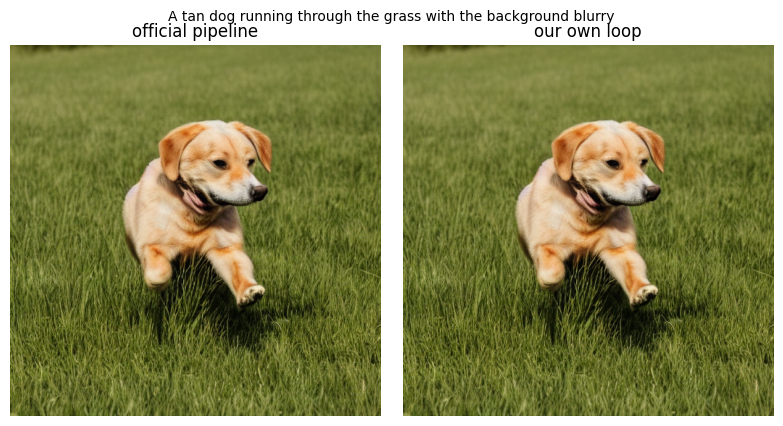

In [9]:
ref_pipe = StableDiffusionPipeline(vae=vae, text_encoder=text_encoder, tokenizer=tokenizer, unet=unet,
                                   scheduler=make_scheduler(), safety_checker=None, feature_extractor=None,
                                   requires_safety_checker=False)
ref_pipe.set_progress_bar_config(disable=True)

if device == "cuda": torch.cuda.reset_peak_memory_stats()
sync(); t0 = time.time()
ref_img = ref_pipe(TRACE_PROMPT, num_inference_steps=STEPS, guidance_scale=GUIDANCE,
                   generator=torch.Generator(device=device).manual_seed(SEED)).images[0]
sync(); ref_secs = time.time() - t0

sync(); t0 = time.time()
our_img, step_log, previews = generate(clip_embed([TRACE_PROMPT]), clip_embed([""]), SEED, record=True)
sync(); our_secs = time.time() - t0
GEN_PEAK_GB = peak_gb()

def pixel_diff(a, b):
    return round(float(np.abs(np.asarray(a, dtype=np.float32) - np.asarray(b, dtype=np.float32)).mean()), 3)

verify = {"prompt": TRACE_PROMPT, "seed": SEED,
          "mean_pixel_diff_ours_vs_pipeline (0-255)": pixel_diff(our_img, ref_img),
          "seconds_pipeline": round(ref_secs, 2), "seconds_ours_with_diagnostics": round(our_secs, 2),
          "peak_gpu_gb": GEN_PEAK_GB}
try:
    urllib.request.urlretrieve(f"{REPO_RAW}/baseline_gallery/generated/gen_00.png", "m1_gen_00.png")
    verify["mean_pixel_diff_ours_vs_milestone1 (0-255)"] = pixel_diff(our_img, Image.open("m1_gen_00.png").convert("RGB"))
except Exception as e:
    print("Could not download the Milestone 1 image:", e)

our_img.save(os.path.join(OUT, "images", "ours_seed42.png"))
ref_img.save(os.path.join(OUT, "images", "pipeline_seed42.png"))
with open(os.path.join(OUT, "verify.json"), "w") as f:
    json.dump(verify, f, indent=2)
for k, v in verify.items():
    print(f"{k:45s} {v}")
print("A difference below about 1 (out of 255) means the images are the same to the eye.")

fig, ax = plt.subplots(1, 2, figsize=(8, 4.3))
for a, im, t in zip(ax, [ref_img, our_img], ["official pipeline", "our own loop"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.suptitle(textwrap.fill(TRACE_PROMPT, 70), fontsize=10); plt.tight_layout()
plt.savefig(os.path.join(OUT, "verify_side_by_side.png"), dpi=100, bbox_inches="tight"); plt.show()

## 8. Sampler diagnostics (what happens during the 30 steps)
This is an inference-only pipeline, so instead of a training loss we log what the sampler does at each step:
- **latent spread** falls as noise is removed;
- **text signal** (`‖cond − uncond‖`) shows how much the prompt changes the U-Net's prediction at each step;
- the **previews** show the model's current guess of the final image: the rough layout appears in the first few steps, details come at the end.

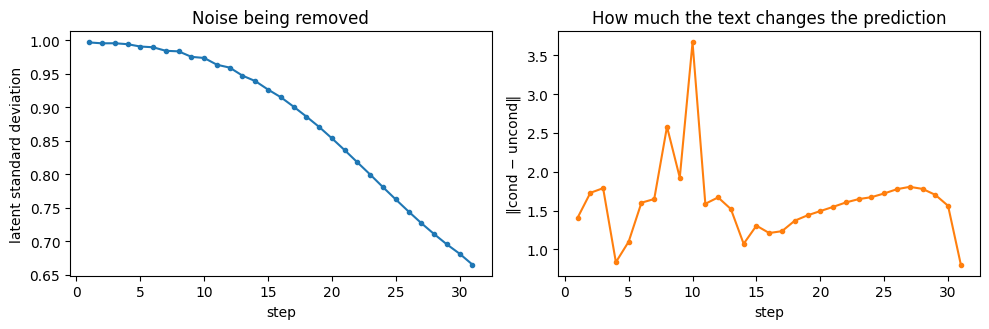

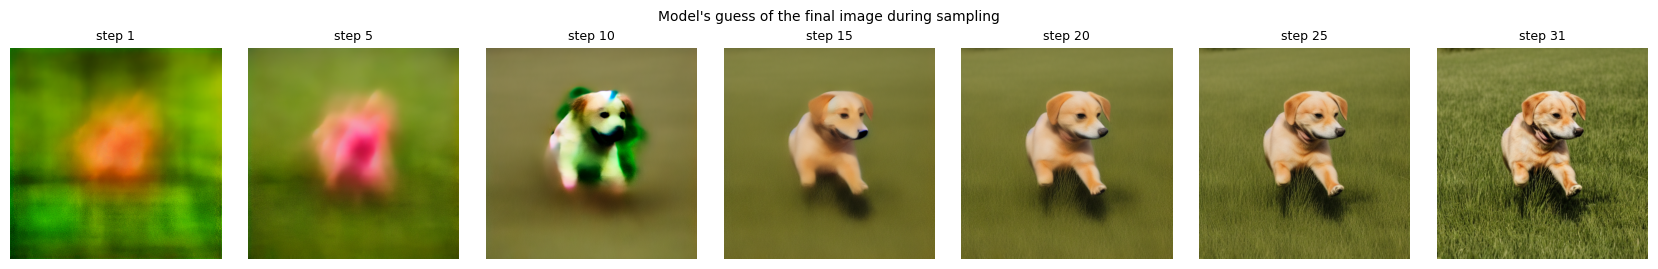

In [10]:
steps_df = pd.DataFrame(step_log)
steps_df.to_csv(os.path.join(OUT, "sampler_diagnostics.csv"), index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(steps_df["step"], steps_df["latent_std"], marker="o", ms=3)
ax[0].set_xlabel("step"); ax[0].set_ylabel("latent standard deviation"); ax[0].set_title("Noise being removed")
ax[1].plot(steps_df["step"], steps_df["text_signal_norm"], marker="o", ms=3, color="tab:orange")
ax[1].set_xlabel("step"); ax[1].set_ylabel("‖cond − uncond‖"); ax[1].set_title("How much the text changes the prediction")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "sampler_diagnostics.png"), dpi=120, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(1, len(previews), figsize=(2.4 * len(previews), 2.7))
for a, (s, im) in zip(ax, previews.items()):
    a.imshow(im); a.set_title(f"step {s}", fontsize=9); a.axis("off")
plt.suptitle("Model's guess of the final image during sampling", fontsize=10); plt.tight_layout()
plt.savefig(os.path.join(OUT, "denoising_progress.png"), dpi=100, bbox_inches="tight"); plt.show()

## 9. Load the CLIP scorer

In [11]:
from transformers import CLIPModel, CLIPProcessor

clip_proc = CLIPProcessor.from_pretrained(CLIP_SCORER)
clip = CLIPModel.from_pretrained(CLIP_SCORER).to(device=device, dtype=dtype).eval()

@torch.no_grad()
def score_text(texts):
    inp = clip_proc.tokenizer(texts, padding="max_length", max_length=77, truncation=True, return_tensors="pt").to(device)
    e = clip.text_projection(clip.text_model(**inp).pooler_output)
    return torch.nn.functional.normalize(e.float(), dim=-1)

@torch.no_grad()
def score_image(images):
    pix = clip_proc(images=images, return_tensors="pt")["pixel_values"].to(device, dtype)
    e = clip.visual_projection(clip.vision_model(pixel_values=pix).pooler_output)
    return torch.nn.functional.normalize(e.float(), dim=-1)

def clip_score(image, text):
    # CLIP score = 100 x cosine similarity between the image and its caption (higher = better match)
    return round(100 * float((score_image([image]) * score_text([text])).sum()), 2)

def pairwise_similarity(images):
    # mean CLIP similarity between different images (lower = more variety)
    e = score_image(images)
    s = e @ e.T
    return round(100 * float(s[~torch.eye(len(images), dtype=bool, device=s.device)].mean()), 2)

print("CLIP scorer loaded:", CLIP_SCORER)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIP scorer loaded: openai/clip-vit-large-patch14


## 10. Conditioning check: does the text really control the image?
We generate images for 6 test prompts, plus the **empty prompt**, all with **the same seed**. The starting noise is identical, so any difference comes only from the text. Then CLIP scores every image against every prompt. If the conditioning works, each image matches **its own** prompt best (the diagonal of the table).

,prompt #0,prompt #1,prompt #3,prompt #10,prompt #12,prompt #14
image #0,26.6,16.9,12.400000,6.5,4.5,11.200000
image #1,13.3,32.5,9.200000,5.2,0.1,9.800000
image #3,8.4,5.7,24.299999,5.5,8.3,8.700000
image #10,3.4,7.6,6.000000,26.5,13.9,6.200000
image #12,7.2,7.0,7.600000,8.9,29.0,7.400000
image #14,8.0,8.4,5.900000,4.5,6.9,25.299999


{'seed': 42, 'prompt_ids': [0, 1, 3, 10, 12, 14], 'images_matching_own_prompt_best': '6 of 6', 'mean_clip_matched': 27.37, 'mean_clip_mismatched': 7.82, 'mean_clip_empty_prompt_image': 11.31}


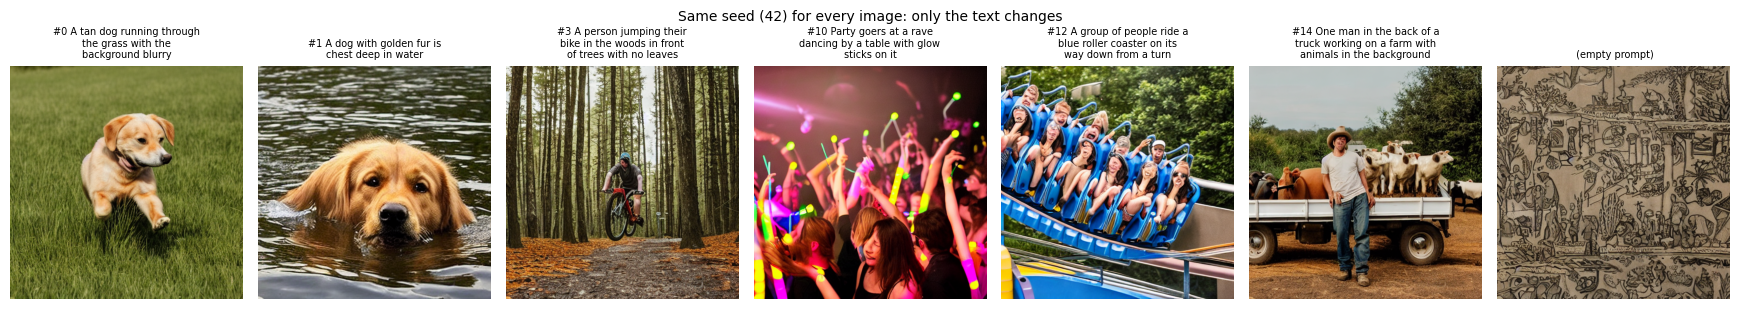

In [12]:
CHECK_IDS = [0, 1, 3, 10, 12, 14]
check_prompts = [m1.loc[i, "caption"] for i in CHECK_IDS]
UNCOND = clip_embed([""])
check_imgs = []
for i, p in zip(CHECK_IDS, check_prompts):
    img, _, _ = generate(clip_embed([p]), UNCOND, SEED)
    img.save(os.path.join(OUT, "images", f"check_{i:02d}.png")); check_imgs.append(img)
empty_img, _, _ = generate(UNCOND, UNCOND, SEED)
empty_img.save(os.path.join(OUT, "images", "check_empty_prompt.png"))

M = (100 * score_image(check_imgs) @ score_text(check_prompts).T).cpu().numpy()
labels = [f"#{i}" for i in CHECK_IDS]
mat = pd.DataFrame(M.round(1), index=[f"image {l}" for l in labels], columns=[f"prompt {l}" for l in labels])
display(mat)
diag_hits = int((M.argmax(axis=1) == np.arange(len(M))).sum())
matched, mismatched = float(np.diag(M).mean()), float(M[~np.eye(len(M), dtype=bool)].mean())
empty_vs_prompts = float((100 * score_image([empty_img]) @ score_text(check_prompts).T).mean())
cond_check = {"seed": SEED, "prompt_ids": CHECK_IDS, "images_matching_own_prompt_best": f"{diag_hits} of {len(M)}",
              "mean_clip_matched": round(matched, 2), "mean_clip_mismatched": round(mismatched, 2),
              "mean_clip_empty_prompt_image": round(empty_vs_prompts, 2)}
mat.to_csv(os.path.join(OUT, "conditioning_matrix.csv"))
with open(os.path.join(OUT, "conditioning_check.json"), "w") as f:
    json.dump(cond_check, f, indent=2)
print(cond_check)

fig, ax = plt.subplots(1, len(check_imgs) + 1, figsize=(2.5 * (len(check_imgs) + 1), 3.3))
for a, im, p, l in zip(ax, check_imgs + [empty_img], check_prompts + ["(empty prompt)"], labels + [""]):
    a.imshow(im); a.axis("off"); a.set_title(textwrap.fill(f"{l} {p}", 28), fontsize=7)
plt.suptitle(f"Same seed ({SEED}) for every image: only the text changes", fontsize=10); plt.tight_layout()
plt.savefig(os.path.join(OUT, "conditioning_check.png"), dpi=100, bbox_inches="tight"); plt.show()

## 11. Training: a BERT → CLIP adapter
The assignment allows **CLIP or BERT** as the text encoder. Stable Diffusion was trained with CLIP embeddings, so raw BERT embeddings "speak a different language" to the U-Net. We train a small **adapter** that translates them:

`caption → BERT (frozen) → adapter (trained) → 77 × 768 embedding → U-Net (frozen)`

- **Adapter:** 77 learned query vectors and a 2-layer Transformer decoder that reads the BERT tokens through cross-attention (about 17M parameters). Only the adapter is trained.
- **Training target:** the CLIP text encoder's embedding of the same caption. **Loss:** mean squared error (on standardized values).
- **Data:** all cleaned captions of the **train split** (each photo has up to 5), about 7,600. **Validation:** the 200 **val** captions. Test captions are never used for training.

Step 1: compute the BERT inputs and CLIP targets once.

In [13]:
from transformers import AutoTokenizer, AutoModel

bert_tok = AutoTokenizer.from_pretrained(BERT_MODEL)
bert = AutoModel.from_pretrained(BERT_MODEL).to(device).eval()
bert.requires_grad_(False)
BERT_LEN = 64

@torch.no_grad()
def bert_embed(texts):
    b = bert_tok(texts, padding="max_length", max_length=BERT_LEN, truncation=True, return_tensors="pt").to(device)
    return bert(**b).last_hidden_state, b["attention_mask"]

train_df, val_df = df[df["split"] == "train"], df[df["split"] == "val"]
train_caps = sorted(set(train_df["caption"]) | {c for s in train_df["alt_captions"] for c in json.loads(s)})
val_caps = val_df["caption"].tolist()

@torch.no_grad()
def build_features(caps, bs=128):
    H, Mk, T = [], [], []
    for i in range(0, len(caps), bs):
        h, m = bert_embed(caps[i:i + bs])
        H.append(h.half()); Mk.append(m.bool()); T.append(clip_embed(caps[i:i + bs]).half())
    return torch.cat(H), torch.cat(Mk), torch.cat(T)

t0 = time.time()
H_tr, M_tr, T_tr = build_features(train_caps)
H_va, M_va, T_va = build_features(val_caps)
FEAT_SECS = round(time.time() - t0, 1)

# standardize the CLIP targets per position and dimension (computed on train only)
mu = torch.mean(T_tr, dim=0, dtype=torch.float32)
var = torch.zeros_like(mu)
for i in range(0, len(T_tr), 512):
    var += ((T_tr[i:i + 512].float() - mu) ** 2).sum(0)
sd = (var / (len(T_tr) - 1)).sqrt().clamp_min(1e-3)
def standardize(t): return (t.float() - mu) / sd

print(f"train captions: {len(train_caps)} | val captions: {len(val_caps)} | features in {FEAT_SECS}s")
print("BERT input:", tuple(H_tr.shape), "| CLIP target:", tuple(T_tr.shape))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


train captions: 7613 | val captions: 200 | features in 29.6s
BERT input: (7613, 64, 768) | CLIP target: (7613, 77, 768)


Step 2: the adapter and the training loop. We log the loss at every step, the validation loss after every epoch, the time and the GPU memory, and keep the best epoch (lowest validation loss). As a reference, a model that always outputs the average embedding would get a validation loss of about **1.0**.

In [14]:
class BertToClipAdapter(nn.Module):
    def __init__(self, d_in=768, d=768, n_tokens=77, layers=2, heads=8):
        super().__init__()
        self.inp = nn.Linear(d_in, d)
        self.queries = nn.Parameter(torch.randn(n_tokens, d) * 0.02)      # one learned vector per output position
        layer = nn.TransformerDecoderLayer(d, heads, dim_feedforward=2048, dropout=0.1, batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(layer, layers)
        self.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 768))

    def forward(self, h, mask):
        memory = self.inp(h)
        q = self.queries.unsqueeze(0).expand(h.size(0), -1, -1)
        return self.out(self.decoder(q, memory, memory_key_padding_mask=~mask))

torch.manual_seed(SEED)
adapter = BertToClipAdapter().to(device)
ADAPTER_PARAMS_M = n_params(adapter)
EPOCHS, BS, LR = 15, 64, 3e-4
steps_per_epoch = math.ceil(len(train_caps) / BS)
opt = torch.optim.AdamW(adapter.parameters(), lr=LR, weight_decay=0.01)
lr_sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * steps_per_epoch, pct_start=0.1)

@torch.no_grad()
def evaluate():
    adapter.eval()
    pred = adapter(H_va.float(), M_va)
    loss = F.mse_loss(pred, standardize(T_va)).item()
    raw = pred * sd + mu
    cos = F.cosine_similarity(raw, T_va.float(), dim=-1)[:, 1:].mean().item()   # skip the fixed start token
    return loss, cos

mean_baseline_loss = F.mse_loss(torch.zeros_like(T_va, dtype=torch.float32), standardize(T_va)).item()
if device == "cuda": torch.cuda.reset_peak_memory_stats()
step_rows, epoch_rows, best = [], [], (float("inf"), None, 0)
g_cpu = torch.Generator().manual_seed(SEED)
train_t0, step = time.time(), 0
for epoch in range(1, EPOCHS + 1):
    adapter.train(); e_t0, e_losses = time.time(), []
    for idx in torch.randperm(len(train_caps), generator=g_cpu).split(BS):
        idx = idx.to(device)
        loss = F.mse_loss(adapter(H_tr[idx].float(), M_tr[idx]), standardize(T_tr[idx]))
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(adapter.parameters(), 1.0)
        opt.step(); lr_sched.step(); step += 1
        e_losses.append(loss.item())
        step_rows.append({"step": step, "epoch": epoch, "train_loss": round(loss.item(), 5), "lr": lr_sched.get_last_lr()[0]})
    sync()
    val_loss, val_cos = evaluate()
    epoch_rows.append({"epoch": epoch, "train_loss": round(float(np.mean(e_losses)), 5), "val_loss": round(val_loss, 5),
                       "val_token_cosine": round(val_cos, 4), "epoch_seconds": round(time.time() - e_t0, 1),
                       "peak_gpu_gb": peak_gb()})
    if val_loss < best[0]:
        best = (val_loss, copy.deepcopy(adapter.state_dict()), epoch)
    r = epoch_rows[-1]
    print(f"epoch {epoch:2d} | train {r['train_loss']:.4f} | val {r['val_loss']:.4f} | "
          f"val cosine {r['val_token_cosine']:.3f} | {r['epoch_seconds']}s | {r['peak_gpu_gb']} GB")
TRAIN_SECS = round(time.time() - train_t0, 1)
adapter.load_state_dict(best[1]); adapter.eval()
print(f"Training time: {TRAIN_SECS}s | best epoch {best[2]} (val loss {best[0]:.4f}) | "
      f"'always the average' reference: {mean_baseline_loss:.4f}")

steps_log, epochs_log = pd.DataFrame(step_rows), pd.DataFrame(epoch_rows)
steps_log.to_csv(os.path.join(OUT, "adapter_train_steps.csv"), index=False)
epochs_log.to_csv(os.path.join(OUT, "adapter_train_epochs.csv"), index=False)
torch.save({k: v.half() for k, v in adapter.state_dict().items()} | {"mu": mu.half(), "sd": sd.half()}, "bert_adapter.pt")

epoch  1 | train 0.9911 | val 0.8532 | val cosine 0.608 | 20.3s | 6.28 GB
epoch  2 | train 0.7508 | val 0.6986 | val cosine 0.693 | 20.0s | 6.35 GB
epoch  3 | train 0.6333 | val 0.6314 | val cosine 0.728 | 20.1s | 6.35 GB
epoch  4 | train 0.5635 | val 0.5940 | val cosine 0.747 | 20.2s | 6.35 GB
epoch  5 | train 0.5152 | val 0.5683 | val cosine 0.759 | 20.3s | 6.35 GB
epoch  6 | train 0.4762 | val 0.5493 | val cosine 0.768 | 20.4s | 6.35 GB
epoch  7 | train 0.4441 | val 0.5379 | val cosine 0.774 | 20.5s | 6.35 GB
epoch  8 | train 0.4165 | val 0.5291 | val cosine 0.778 | 20.5s | 6.35 GB
epoch  9 | train 0.3932 | val 0.5253 | val cosine 0.780 | 20.6s | 6.35 GB
epoch 10 | train 0.3747 | val 0.5194 | val cosine 0.783 | 20.6s | 6.35 GB
epoch 11 | train 0.3604 | val 0.5179 | val cosine 0.784 | 20.6s | 6.35 GB
epoch 12 | train 0.3501 | val 0.5166 | val cosine 0.785 | 20.7s | 6.35 GB
epoch 13 | train 0.3431 | val 0.5174 | val cosine 0.784 | 20.7s | 6.35 GB
epoch 14 | train 0.3391 | val 0.5170 |

Step 3: the loss curves.

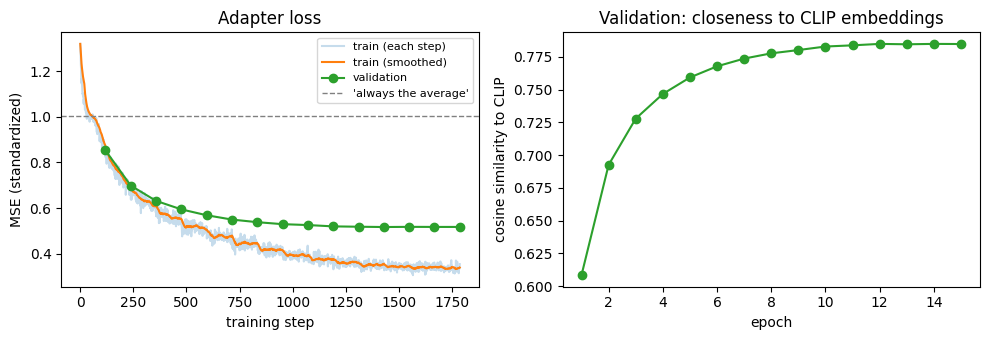

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
smooth = steps_log["train_loss"].rolling(20, min_periods=1).mean()
ax[0].plot(steps_log["step"], steps_log["train_loss"], alpha=0.25, label="train (each step)")
ax[0].plot(steps_log["step"], smooth, label="train (smoothed)")
ax[0].plot(epochs_log["epoch"] * steps_per_epoch, epochs_log["val_loss"], "o-", label="validation")
ax[0].axhline(mean_baseline_loss, ls="--", c="gray", lw=1, label="'always the average'")
ax[0].set_xlabel("training step"); ax[0].set_ylabel("MSE (standardized)"); ax[0].set_title("Adapter loss"); ax[0].legend(fontsize=8)
ax[1].plot(epochs_log["epoch"], epochs_log["val_token_cosine"], "o-", color="tab:green")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("cosine similarity to CLIP"); ax[1].set_title("Validation: closeness to CLIP embeddings")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "adapter_loss_curve.png"), dpi=120, bbox_inches="tight"); plt.show()

## 12. Generate with CLIP, raw BERT and BERT + adapter
Same 6 test prompts, same seed for each prompt (42 + id, as in Milestone 1). Three ways to make the conditioning embedding:
- **CLIP:** the normal Stable Diffusion text encoder;
- **raw BERT:** BERT's 768-number token vectors plugged straight into the U-Net, without the adapter (the sizes fit, but the meaning does not);
- **BERT + adapter:** BERT translated by our trained adapter.

Each path uses its own embedding of the empty prompt for guidance.

,mean,min,max
encoder,,,
CLIP,28.78,25.78,31.29
raw BERT,9.88,2.20,18.14
BERT + adapter,21.40,15.05,24.00


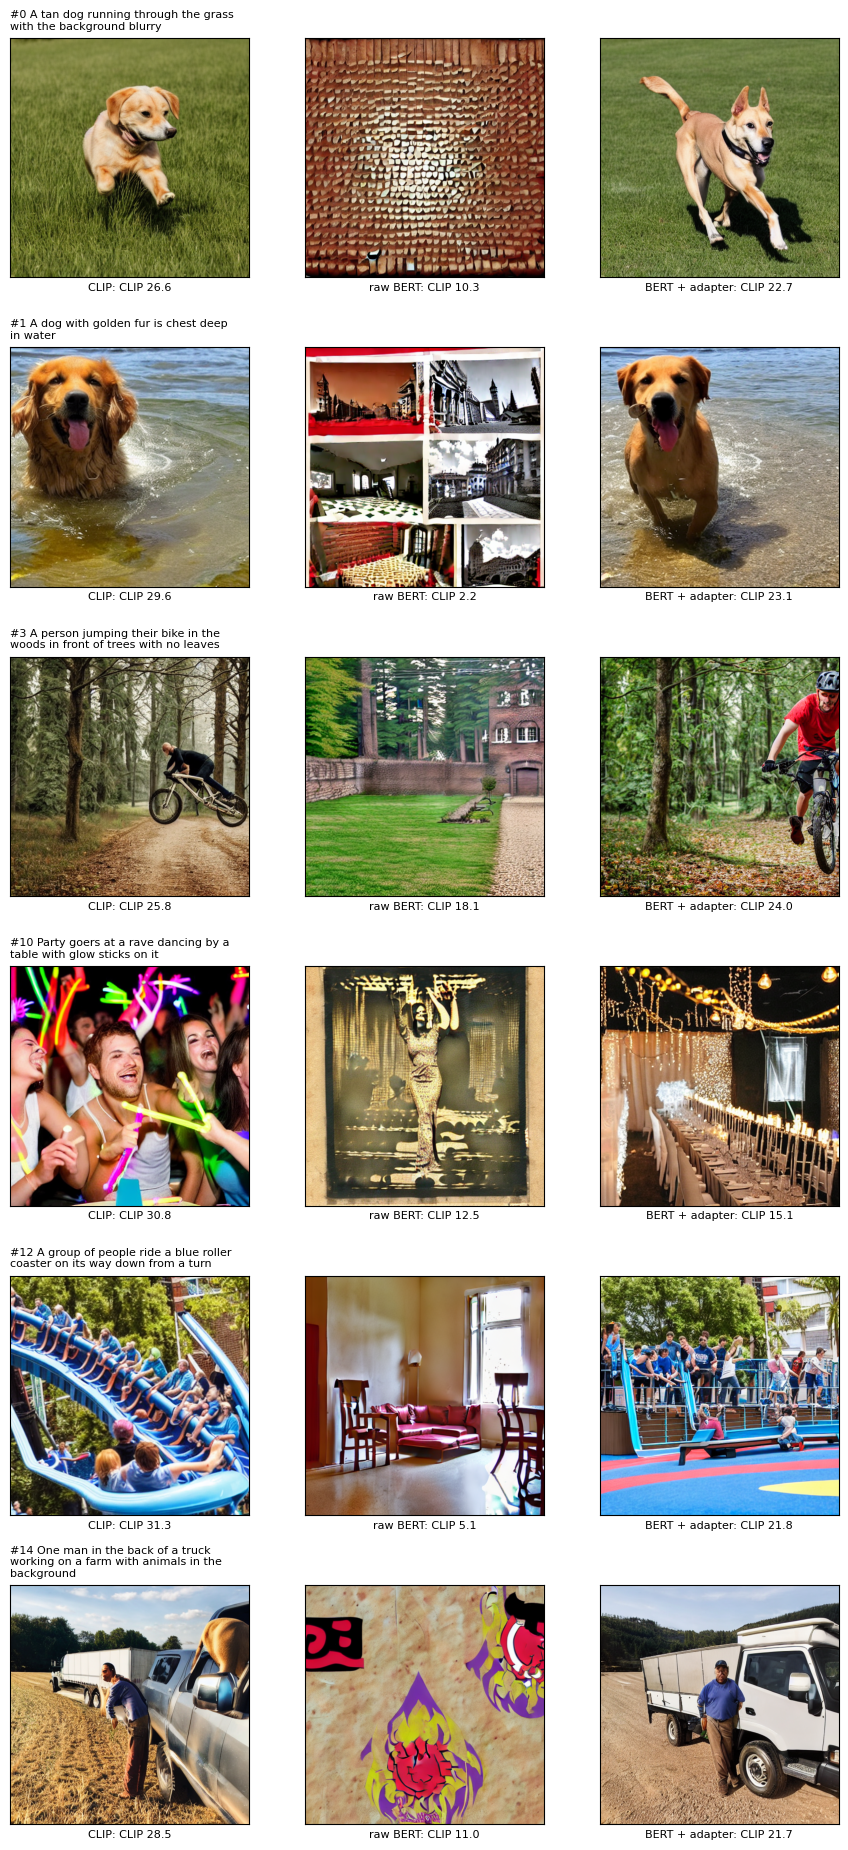

In [16]:
@torch.no_grad()
def bert_raw_embed(texts):
    return bert_embed(texts)[0].to(dtype)

@torch.no_grad()
def adapter_embed(texts):
    h, m = bert_embed(texts)
    return (adapter(h.float(), m.bool()) * sd + mu).to(dtype)

ENCODERS = {"CLIP": clip_embed, "raw BERT": bert_raw_embed, "BERT + adapter": adapter_embed}
rows, grid = [], {}
for name, enc in ENCODERS.items():
    unc = enc([""])
    for i in CHECK_IDS:
        p = m1.loc[i, "caption"]
        sync(); t0 = time.time()
        img, _, _ = generate(enc([p]), unc, SEED + i)
        sync()
        fname = f"encoder_{name.replace(' + ', '_').replace(' ', '_').lower()}_{i:02d}.png"
        img.save(os.path.join(OUT, "images", fname)); grid[(name, i)] = img
        rows.append({"encoder": name, "prompt_id": i, "prompt": p, "seed": SEED + i,
                     "seconds": round(time.time() - t0, 2), "clip_score": clip_score(img, p), "file": fname})
enc_df = pd.DataFrame(rows)
enc_df.to_csv(os.path.join(OUT, "encoder_comparison.csv"), index=False)
enc_summary = enc_df.groupby("encoder", sort=False)["clip_score"].agg(["mean", "min", "max"]).round(2)
display(enc_summary)

fig, ax = plt.subplots(len(CHECK_IDS), len(ENCODERS), figsize=(3.0 * len(ENCODERS), 3.1 * len(CHECK_IDS)))
for r, i in enumerate(CHECK_IDS):
    for c, name in enumerate(ENCODERS):
        a = ax[r, c]; a.imshow(grid[(name, i)]); a.set_xticks([]); a.set_yticks([])
        s = enc_df[(enc_df.encoder == name) & (enc_df.prompt_id == i)]["clip_score"].iloc[0]
        a.set_xlabel(f"{name}: CLIP {s:.1f}", fontsize=8)
        if c == 0:
            a.set_title(textwrap.fill(f"#{i} {m1.loc[i, 'caption']}", 40), fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "encoder_comparison.png"), dpi=90, bbox_inches="tight"); plt.show()

## 13. Save the run summary and download

In [17]:
import diffusers, transformers
summary = {
    "gpu": GPU, "python": platform.python_version(), "torch": torch.__version__,
    "diffusers": diffusers.__version__, "transformers": transformers.__version__,
    "sd_model": SD_MODEL, "bert_model": BERT_MODEL, "steps": STEPS, "guidance": GUIDANCE, "seed": SEED,
    "parts": parts.to_dict(orient="records"), "trace": trace, "verify": verify,
    "conditioning_check": cond_check,
    "adapter": {"params_M": ADAPTER_PARAMS_M, "epochs": EPOCHS, "batch_size": BS, "lr": LR,
                "train_captions": len(train_caps), "val_captions": len(val_caps),
                "feature_seconds": FEAT_SECS, "train_seconds": TRAIN_SECS, "best_epoch": best[2],
                "best_val_loss": round(best[0], 4), "always_average_val_loss": round(mean_baseline_loss, 4),
                "final": epoch_rows[-1], "peak_gpu_gb_training": max(r["peak_gpu_gb"] for r in epoch_rows)},
    "encoder_comparison_mean_clip": enc_summary["mean"].to_dict(),
    "model_load_seconds": LOAD_SECS, "total_minutes": round((time.time() - T_START) / 60, 1),
}
with open(os.path.join(OUT, "summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps({k: summary[k] for k in ["verify", "conditioning_check", "adapter", "encoder_comparison_mean_clip"]}, indent=2, default=str))

shutil.make_archive("m2_integration", "zip", OUT)
print("Created m2_integration.zip:", sorted(os.listdir(OUT)))
try:
    from google.colab import files
    files.download("m2_integration.zip")
except Exception:
    print("Download m2_integration.zip from the file panel on the left.")

{
  "verify": {
    "prompt": "A tan dog running through the grass with the background blurry",
    "seed": 42,
    "mean_pixel_diff_ours_vs_pipeline (0-255)": 0.0,
    "seconds_pipeline": 4.62,
    "seconds_ours_with_diagnostics": 5.78,
    "peak_gpu_gb": 2.81,
    "mean_pixel_diff_ours_vs_milestone1 (0-255)": 0.0
  },
  "conditioning_check": {
    "seed": 42,
    "prompt_ids": [
      0,
      1,
      3,
      10,
      12,
      14
    ],
    "images_matching_own_prompt_best": "6 of 6",
    "mean_clip_matched": 27.37,
    "mean_clip_mismatched": 7.82,
    "mean_clip_empty_prompt_image": 11.31
  },
  "adapter": {
    "params_M": 17.0,
    "epochs": 15,
    "batch_size": 64,
    "lr": 0.0003,
    "train_captions": 7613,
    "val_captions": 200,
    "feature_seconds": 29.6,
    "train_seconds": 307.1,
    "best_epoch": 12,
    "best_val_loss": 0.5166,
    "always_average_val_loss": 1.0046,
    "final": {
      "epoch": 15,
      "train_loss": 0.33726,
      "val_loss": 0.517,
      "v

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>